# Symmetric Frequency Windows

Generate and inspect the 2D bare parameters associated with symmetric windows $[\Omega_A-\lambda,\Omega_A+\lambda]$.

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

resol = 180
plt.rcParams.update({
    "font.family": "serif",
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
})

cwd = Path().resolve()
setup_root = next(
    (
        path
        for path in (cwd, *cwd.parents)
        if (path / "database_fiber").exists() and (path / "src").exists()
    ),
    Path("2d_setup").resolve(),
)
sys.path.insert(0, str(setup_root))

from src.bare_param import (
    bare_param_path,
    get_2d_bare_parameters,
    load_bare_parameters_csv,
    read_bare_parameters_metadata,
    read_target_profile_metadata,
    save_bare_parameters_csv,
    target_profile_path,
)
from src.generate_fiber_geom import load_geometry_by_id

pi = np.pi

<h2>Load target profile</h2>

In [3]:
id_target_profile = 1

target_profile_csv = target_profile_path(id_target_profile)
if not target_profile_csv.exists():
    raise FileNotFoundError(f"Missing target_profile_id{id_target_profile}.csv.")

target_metadata = read_target_profile_metadata(target_profile_csv)
geometry = load_geometry_by_id(target_metadata["id_geom"])
atom_positions = geometry["atom_positions"]
N_A = geometry["N_A"]

Omega_A_tab = target_metadata["Omega_A"]
d_A_tab = target_metadata["d_A"]
if not np.allclose(Omega_A_tab, Omega_A_tab[0]):
    raise ValueError("Symmetric windows require a common atomic frequency Omega_A.")
Omega_A = float(Omega_A_tab[0])

print(f"Target profile: target_profile_id{id_target_profile}.csv")
print(f"Geometry: geometry_id{target_metadata['id_geom']}, N_A={N_A}")
print(f"Omega_A = {Omega_A / pi:.6g} pi")
print(f"Reference window = [{target_metadata['reference_ir_cutoff'] / pi:.6g} pi, {target_metadata['reference_uv_cutoff'] / pi:.6g} pi]")


Target profile: target_profile_id1.csv
Geometry: geometry_id5, N_A=10
Omega_A = 10 pi
Reference window = [0 pi, 20 pi]


<h2>Choose symmetric windows</h2>

In [4]:
# Free parameter: edit this set as needed.
lambda_values = pi * np.linspace(2, 9.9, 20)

windows = [
    {
        "lambda": float(lbda),
        "ir_cutoff": Omega_A - float(lbda),
        "uv_cutoff": Omega_A + float(lbda),
    }
    for lbda in lambda_values
]

pd.DataFrame(
    {
        "lambda/pi": [window["lambda"] / pi for window in windows],
        "ir_cutoff/pi": [window["ir_cutoff"] / pi for window in windows],
        "uv_cutoff/pi": [window["uv_cutoff"] / pi for window in windows],
    }
)

,lambda/pi,ir_cutoff/pi,uv_cutoff/pi
0,2.000000,8.000000,12.000000
1,2.415789,7.584211,12.415789
2,2.831579,7.168421,12.831579
3,3.247368,6.752632,13.247368
4,3.663158,6.336842,13.663158
5,4.078947,5.921053,14.078947
6,4.494737,5.505263,14.494737
7,4.910526,5.089474,14.910526
8,5.326316,4.673684,15.326316
9,5.742105,4.257895,15.742105


<h2>Generate bare parameters</h2>

In [5]:
generated_rows = []

for window in tqdm(windows, desc="symmetric windows"):
    cutoffs = {
        "ir_cutoff": window["ir_cutoff"],
        "uv_cutoff": window["uv_cutoff"],
    }
    Omega_0_tab, d_0_tab = get_2d_bare_parameters(
        target_profile_csv,
        atom_positions,
        cutoffs,
    )

    output_path = bare_param_path()
    save_bare_parameters_csv(Omega_0_tab, d_0_tab, target_metadata, cutoffs, output_path)
    bare_param_id = int(output_path.stem.removeprefix("bare_param_id"))

    generated_rows.append(
        {
            "bare_param_id": bare_param_id,
            "lambda_pi": window["lambda"] / pi,
            "ir_cutoff_pi": cutoffs["ir_cutoff"] / pi,
            "uv_cutoff_pi": cutoffs["uv_cutoff"] / pi,
            "path": output_path,
        }
    )

generated = pd.DataFrame(generated_rows)
generated


symmetric windows:   0%|          | 0/20 [00:00<?, ?it/s]

/Users/romainpiron/Documents/NII_local/waveguide-qed-simulator/2d_setup/src/bare_param.py:535: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  value, _ = quad(


,bare_param_id,lambda_pi,ir_cutoff_pi,uv_cutoff_pi,path
0,5,2.000000,8.000000,12.000000,/Users/romainpiron/Documents/NII_local/wavegui...
1,6,2.415789,7.584211,12.415789,/Users/romainpiron/Documents/NII_local/wavegui...
2,7,2.831579,7.168421,12.831579,/Users/romainpiron/Documents/NII_local/wavegui...
3,8,3.247368,6.752632,13.247368,/Users/romainpiron/Documents/NII_local/wavegui...
4,9,3.663158,6.336842,13.663158,/Users/romainpiron/Documents/NII_local/wavegui...
5,10,4.078947,5.921053,14.078947,/Users/romainpiron/Documents/NII_local/wavegui...
6,11,4.494737,5.505263,14.494737,/Users/romainpiron/Documents/NII_local/wavegui...
7,12,4.910526,5.089474,14.910526,/Users/romainpiron/Documents/NII_local/wavegui...
8,13,5.326316,4.673684,15.326316,/Users/romainpiron/Documents/NII_local/wavegui...
9,14,5.742105,4.257895,15.742105,/Users/romainpiron/Documents/NII_local/wavegui...


<h2>Load saved bare parameters</h2>

In [6]:
# Free parameters: choose the saved ids to inspect.
bare_param_id_start = 5
bare_param_id_stop = 24
bare_param_ids = range(bare_param_id_start, bare_param_id_stop + 1)

loaded_rows = []
for bare_param_id in bare_param_ids:
    path = bare_param_path(bare_param_id)
    if not path.exists():
        raise FileNotFoundError(f"Missing bare_param_id{bare_param_id}.csv.")

    metadata = read_bare_parameters_metadata(path)
    if metadata["id_target_profile"] != id_target_profile:
        raise ValueError(
            f"bare_param_id{bare_param_id} was generated from "
            f"target_profile_id{metadata['id_target_profile']}, not target_profile_id{id_target_profile}."
        )

    Omega_0_tab, d_0_tab = load_bare_parameters_csv(path)
    lbda = 0.5 * (metadata["uv_cutoff"] - metadata["ir_cutoff"])
    center = 0.5 * (metadata["uv_cutoff"] + metadata["ir_cutoff"])

    loaded_rows.append(
        {
            "bare_param_id": bare_param_id,
            "lambda": lbda,
            "lambda_pi": lbda / pi,
            "center_pi": center / pi,
            "ir_cutoff_pi": metadata["ir_cutoff"] / pi,
            "uv_cutoff_pi": metadata["uv_cutoff"] / pi,
            "Omega_0": Omega_0_tab,
            "d_0": d_0_tab,
            "path": path,
        }
    )

bare_param_scan = pd.DataFrame(loaded_rows).sort_values("lambda")
bare_param_scan[["bare_param_id", "lambda_pi", "center_pi", "ir_cutoff_pi", "uv_cutoff_pi", "path"]]


,bare_param_id,lambda_pi,center_pi,ir_cutoff_pi,uv_cutoff_pi,path
0,5,2.000000,10.0,8.000000,12.000000,/Users/romainpiron/Documents/NII_local/wavegui...
1,6,2.415789,10.0,7.584211,12.415789,/Users/romainpiron/Documents/NII_local/wavegui...
2,7,2.831579,10.0,7.168421,12.831579,/Users/romainpiron/Documents/NII_local/wavegui...
3,8,3.247368,10.0,6.752632,13.247368,/Users/romainpiron/Documents/NII_local/wavegui...
4,9,3.663158,10.0,6.336842,13.663158,/Users/romainpiron/Documents/NII_local/wavegui...
5,10,4.078947,10.0,5.921053,14.078947,/Users/romainpiron/Documents/NII_local/wavegui...
6,11,4.494737,10.0,5.505263,14.494737,/Users/romainpiron/Documents/NII_local/wavegui...
7,12,4.910526,10.0,5.089474,14.910526,/Users/romainpiron/Documents/NII_local/wavegui...
8,13,5.326316,10.0,4.673684,15.326316,/Users/romainpiron/Documents/NII_local/wavegui...
9,14,5.742105,10.0,4.257895,15.742105,/Users/romainpiron/Documents/NII_local/wavegui...


/var/folders/n2/ld5ngfbx4891xn96x63rbjlm0000gn/T/ipykernel_86497/1733840367.py:27: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=(0, 0.08, 1, 1))


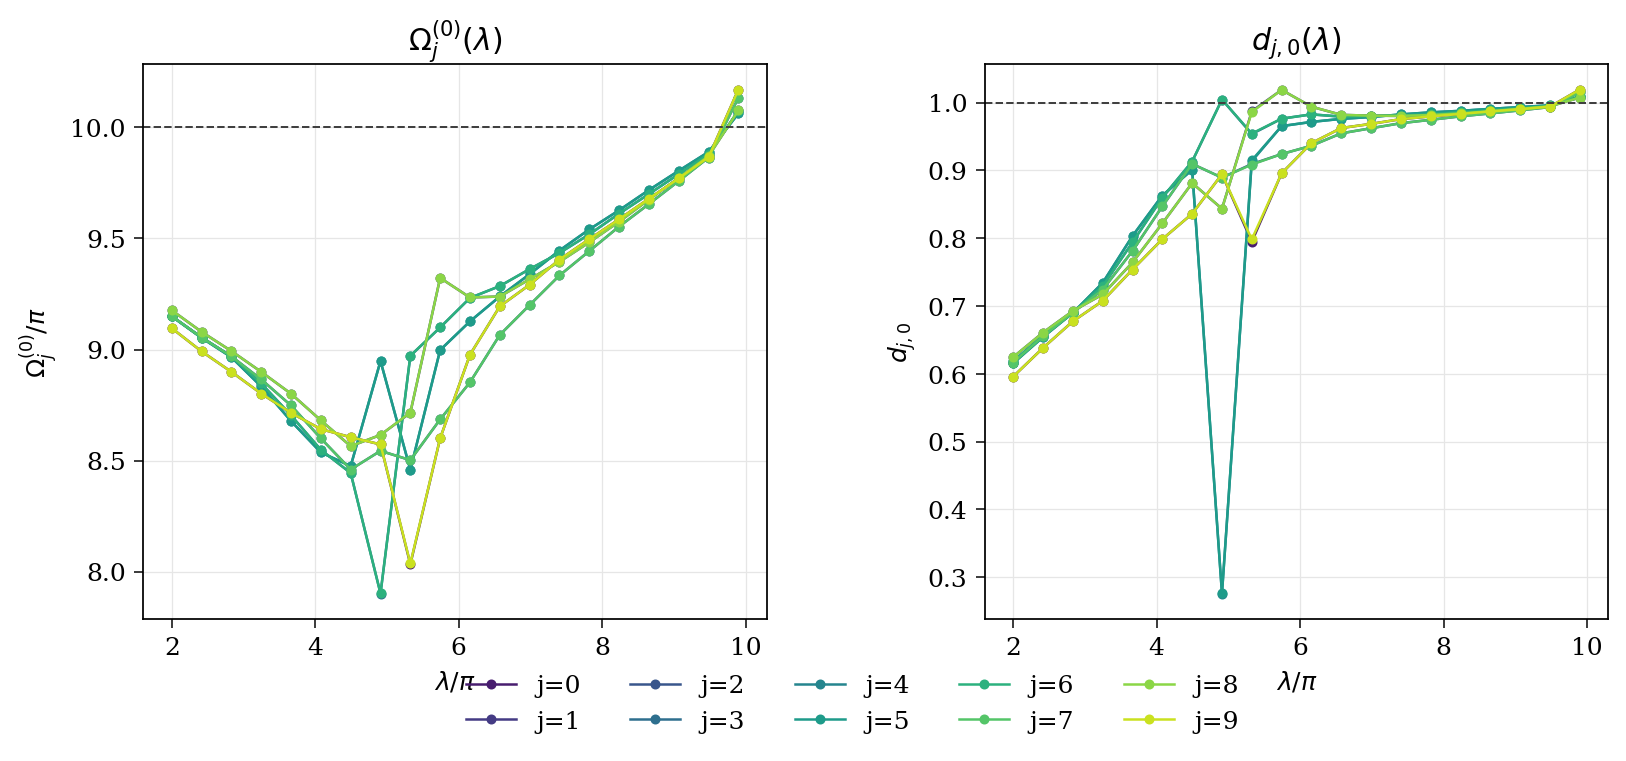

,bare_param_id,lambda_pi,j,Omega_0_pi,d_0,path
0,5,2.0,0,9.095955,0.595908,/Users/romainpiron/Documents/NII_local/wavegui...
1,5,2.0,1,9.176642,0.624639,/Users/romainpiron/Documents/NII_local/wavegui...
2,5,2.0,2,9.150099,0.616593,/Users/romainpiron/Documents/NII_local/wavegui...
3,5,2.0,3,9.149715,0.618525,/Users/romainpiron/Documents/NII_local/wavegui...
4,5,2.0,4,9.149141,0.615579,/Users/romainpiron/Documents/NII_local/wavegui...


In [7]:
lambda_axis = bare_param_scan["lambda"].to_numpy() / pi
Omega_0 = np.vstack(bare_param_scan["Omega_0"].to_numpy())
d_0 = np.vstack(bare_param_scan["d_0"].to_numpy())

fig, (omega_ax, d_ax) = plt.subplots(1, 2, figsize=(10.5, 4), dpi=resol, gridspec_kw={"wspace": 0.35})
colors = plt.cm.viridis(np.linspace(0.08, 0.92, N_A))

for j, color in enumerate(colors):
    omega_ax.plot(lambda_axis, Omega_0[:, j] / pi, marker="o", markersize=3, linewidth=1.0, color=color, label=f"j={j}")
    d_ax.plot(lambda_axis, d_0[:, j], marker="o", markersize=3, linewidth=1.0, color=color, label=f"j={j}")

omega_ax.axhline(Omega_A / pi, color="0.25", linestyle="--", linewidth=0.8)
d_ax.axhline(np.mean(d_A_tab), color="0.25", linestyle="--", linewidth=0.8)

omega_ax.set_title(r"$\Omega_j^{(0)}(\lambda)$", fontweight="bold")
omega_ax.set_xlabel(r"$\lambda / \pi$")
omega_ax.set_ylabel(r"$\Omega_j^{(0)} / \pi$")
omega_ax.grid(color="0.9", linewidth=0.5)

d_ax.set_title(r"$d_{j,0}(\lambda)$", fontweight="bold")
d_ax.set_xlabel(r"$\lambda / \pi$")
d_ax.set_ylabel(r"$d_{j,0}$")
d_ax.grid(color="0.9", linewidth=0.5)

handles, labels = omega_ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=min(N_A, 5), frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

summary_rows = []
for _, row in bare_param_scan.iterrows():
    for j, (omega_0, d_value) in enumerate(zip(row["Omega_0"], row["d_0"])):
        summary_rows.append(
            {
                "bare_param_id": row["bare_param_id"],
                "lambda_pi": row["lambda_pi"],
                "j": j,
                "Omega_0_pi": omega_0 / pi,
                "d_0": d_value,
                "path": row["path"],
            }
        )

bare_param_vs_lambda = pd.DataFrame(summary_rows)
bare_param_vs_lambda.head()
